In [1]:
import importlib.util
import os
import subprocess
import sys
import urllib.request

# ---- install anything missing into the CURRENT python environment
# (works in Colab, in a venv, or system python; skips what is already there)
REQUIREMENTS = {
    "torch": "torch",
    "gymnasium": "gymnasium[atari,accept-rom-license]",
    "ale_py": "ale-py",
    "cv2": "opencv-python-headless",
    "tensorboardX": "tensorboardX",
    "matplotlib": "matplotlib",
}
_missing = [pkg for mod, pkg in REQUIREMENTS.items()
            if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing:", ", ".join(_missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# ---- course helper files
BASE = "https://raw.githubusercontent.com/yandexdataschool/Practical_RL/master/week06_policy_based/"
for fname in ["atari_wrappers.py", "env_batch.py", "runners.py"]:
    if not os.path.exists(fname):
        print("downloading", fname)
        urllib.request.urlretrieve(BASE + fname, fname)

# gymnasium >= 1.4: atari envs live in ale-py, not shimmy — patch the import
# (no-op if shimmy is installed)
import re
with open("atari_wrappers.py") as f:
    _src = f.read()
_patched = re.sub(
    r"(?m)^from shimmy\.atari_env import AtariEnv$",
    "try:\n    from shimmy.atari_env import AtariEnv\nexcept ImportError:\n"
    "    import ale_py\n    from ale_py.env import AtariEnv\n"
    "    gym.register_envs(ale_py)",
    _src,
).replace(
    "except ImportError:\n    import gym\n    import ale_py",
    "except ImportError:\n    import ale_py",
)
if _patched != _src:
    with open("atari_wrappers.py", "w") as f:
        f.write(_patched)

# ---- Colab-only extras: virtual display for rendering
if 'google.colab' in sys.modules and not os.path.exists('.setup_complete'):
    !apt-get install -y xvfb
    !wget -q https://raw.githubusercontent.com/yandexdataschool/Practical_RL/master/xvfb -O ../xvfb
    !touch .setup_complete

# This code creates a virtual display to draw game images on.
# It will have no effect if your machine has a monitor.
if type(os.environ.get("DISPLAY")) is not str or len(os.environ.get("DISPLAY")) == 0:
    !bash ../xvfb start
    os.environ['DISPLAY'] = ':1'


# Implementing Advantage-Actor Critic (A2C)

In this notebook you will implement Advantage Actor Critic algorithm that trains on a batch of Atari 2600 environments running in parallel.

Firstly, we will use environment wrappers implemented in file `atari_wrappers.py`. These wrappers preprocess observations (resize, grayscale, take max between frames, skip frames and stack them together) and rewards. Some of the wrappers help to reset the environment and pass `done` flag equal to `True` when agent dies.
File `env_batch.py` includes implementation of `ParallelEnvBatch` class that allows to run multiple environments in parallel. To create an environment we can use `nature_dqn_env` function. Note that if you are using
PyTorch and not using `tensorboardX` you will need to implement a wrapper that will log **raw** total rewards that the *unwrapped* environment returns and redefine the implemention of `nature_dqn_env` function here.



In [2]:
import numpy as np
import gymnasium as gym
from atari_wrappers import nature_dqn_env


env_name = "SpaceInvadersNoFrameskip-v4"
SEED = 45
nenvs = 16  # change this if you have more than 8 CPU ;)
summaries = "Numpy"  # "Tensorboard" also works; Numpy is portable and keeps plots inline

env = nature_dqn_env(env_name, nenvs=nenvs, summaries=summaries)
obs, _ = env.reset()
assert obs.shape == (nenvs, 4, 84, 84)
assert obs.dtype == np.float32


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
A.L.E: Arcade Learning Environment (vers

Next, we will need to implement a model that predicts logits and values. It is suggested that you use the same model as in [Nature DQN paper](https://www.nature.com/articles/nature14236) with a modification that instead of having a single output layer, it will have two output layers taking as input the output of the last hidden layer. **Note** that this model is different from the model you used in homework where you implemented DQN. You can use your favorite deep learning framework here. We suggest that you use orthogonal initialization with parameter $\sqrt{2}$ for kernels and initialize biases with zeros.

In [3]:
import torch
import torch.nn as nn
from torch.distributions import Categorical

import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# any accelerator: CUDA, Apple MPS, or CPU
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print("device:", device)


def init_layer(m):
    # orthogonal init with gain sqrt(2), zero biases — as suggested
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
        if m.bias is not None:
            nn.init.constant_(m.bias, 0.0)


class Model(nn.Module):
    """Nature DQN conv net with two output heads: policy logits and state value."""

    def __init__(self, n_actions):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4), nn.ReLU(),   # -> 20x20
            nn.Conv2d(32, 64, kernel_size=4, stride=2), nn.ReLU(),  # -> 9x9
            nn.Conv2d(64, 64, kernel_size=3, stride=1), nn.ReLU(),  # -> 7x7
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 512), nn.ReLU(),
        )
        self.policy_head = nn.Linear(512, n_actions)
        self.value_head = nn.Linear(512, 1)
        self.apply(init_layer)

    def forward(self, obs):                       # obs: (N, 4, 84, 84) float32
        h = self.features(obs)
        logits = self.policy_head(h)              # (N, n_actions)
        values = self.value_head(h).squeeze(-1)   # (N,)
        return logits, values


device: mps


You will also need to define and use a policy that wraps the model. While the model computes logits for all actions, the policy will sample actions and also compute their log probabilities.  `policy.act` should return a dictionary of all the arrays that are needed to interact with an environment and train the model.
 Note that actions must be an `np.ndarray` while the other
tensors need to have the type determined by your deep learning framework.

In [4]:
class Policy:
    def __init__(self, model):
        self.model = model

    def reset(self):
        pass  # stateless policy; EnvRunner.reset() calls this

    def act(self, inputs):
        # Implement a policy by calling the model, sampling actions and computing their log probs.
        # Should return a dict containing keys ['actions', 'logits', 'log_probs', 'values'].
        obs = torch.as_tensor(inputs, dtype=torch.float32)
        obs = obs.to(next(self.model.parameters()).device)
        with torch.no_grad():
            logits, values = self.model(obs)
            dist = Categorical(logits=logits)
            actions = dist.sample()
            log_probs = dist.log_prob(actions)
        return {
            "actions": actions.cpu().numpy(),  # must be np.ndarray for env.step
            "logits": logits,
            "log_probs": log_probs,
            "values": values,
        }


Next will pass the environment and policy to a runner that collects partial trajectories from the environment.
The class that does is is already implemented for you.

In [5]:
from runners import EnvRunner

This runner interacts with the environment for a given number of steps and returns a dictionary containing
keys

* 'observations'
* 'rewards'
* 'resets'
* 'actions'
* all other keys that you defined in `Policy`

under each of these keys there is a python `list` of interactions with the environment. This list has length $T$ that is size of partial trajectory. Partial trajectory for given moment `t` is part of `ComputeValueTargets.__call__` input argument `trajectory` from moment `t` to the end (i.e. it's different at each iteration in the algorithm).

To train the part of the model that predicts state values you will need to compute the value targets.
Any callable could be passed to `EnvRunner` to be applied to each partial trajectory after it is collected.
Thus, we can implement and use `ComputeValueTargets` callable.
The formula for the value targets is simple:

$$
\hat v(s_t) = \left( \sum_{t'=0}^{T - 1} \gamma^{t'}r_{t+t'} \right) + \gamma^T \hat{v}(s_{t+T}),
$$

In implementation, however, do not forget to use
`trajectory['resets']` flags to check if you need to add the value targets at the next step when
computing value targets for the current step. You can access `trajectory['state']['latest_observation']`
to get last observations in partial trajectory &mdash; $s_{t+T}$.

In [6]:
class ComputeValueTargets:
    def __init__(self, policy, gamma=0.99):
        self.policy = policy
        self.gamma = gamma

    def __call__(self, trajectory):
        """Compute value targets for a given partial trajectory."""

        # This method should modify trajectory inplace by adding
        # an item with key 'value_targets' to it.
        rewards = np.asarray(trajectory["rewards"], dtype=np.float32)  # (T, N)
        resets = np.asarray(trajectory["resets"], dtype=bool)          # (T, N)
        T, N = rewards.shape

        # bootstrap value of the last observation s_{t+T} for every env
        last_obs = trajectory["state"]["latest_observation"]  # (N, 4, 84, 84)
        device = next(self.policy.model.parameters()).device
        with torch.no_grad():
            _, last_values = self.policy.model(
                torch.as_tensor(last_obs, dtype=torch.float32).to(device)
            )
        acc = last_values.cpu().numpy().astype(np.float32).copy()      # (N,)

        value_targets = np.empty((T, N), dtype=np.float32)
        not_done = (~resets).astype(np.float32)
        for t in reversed(range(T)):
            # acc == discounted value of the state *after* step t
            acc = rewards[t] + self.gamma * acc * not_done[t]
            value_targets[t] = acc
        trajectory["value_targets"] = value_targets


After computing value targets we will transform lists of interactions into tensors
with the first dimension `batch_size` which is equal to `env_steps * num_envs`, i.e. you essentially need
to flatten the first two dimensions.

In [7]:
class MergeTimeBatch:
    """ Merges first two axes typically representing time and env batch. """

    def __call__(self, trajectory):
        # Modify trajectory inplace.
        T = len(trajectory["observations"])
        for key, val in list(trajectory.items()):
            if key == "state":
                continue
            if isinstance(val, list) and val:
                first = val[0]
                if isinstance(first, torch.Tensor):
                    trajectory[key] = torch.stack(val).reshape(-1, *first.shape[1:])
                elif isinstance(first, np.ndarray):
                    trajectory[key] = np.stack(val).reshape(-1, *first.shape[1:])
            elif isinstance(val, np.ndarray) and val.ndim >= 2 and val.shape[0] == T:
                # already a (T, N, ...) array — value_targets
                trajectory[key] = val.reshape(-1, *val.shape[2:])


In [8]:
model = Model(env.action_space.spaces[0].n).to(device)
policy = Policy(model)
runner = EnvRunner(
    env=env,
    policy=policy,
    nsteps=5,
    transforms=[
        ComputeValueTargets(policy),
        MergeTimeBatch(),
    ],
)


Now is the time to implement the advantage actor critic algorithm itself. You can look into your lecture,
[Mnih et al. 2016](https://arxiv.org/abs/1602.01783) paper, and [lecture](https://www.youtube.com/watch?v=Tol_jw5hWnI&list=PLkFD6_40KJIxJMR-j5A1mkxK26gh_qg37&index=20) by Sergey Levine.

In [9]:
class A2C:
    def __init__(self,
                 policy,
                 optimizer,
                 value_loss_coef=0.25,
                 entropy_coef=0.01,
                 max_grad_norm=0.5):
        self.policy = policy
        self.optimizer = optimizer
        self.value_loss_coef = value_loss_coef
        self.entropy_coef = entropy_coef
        self.max_grad_norm = max_grad_norm

    def _forward(self, trajectory):
        # Fresh forward pass WITH gradients over the merged batch.
        # (log_probs / values stored by policy.act were computed under
        # no_grad, so they carry no graph — recompute them here.)
        device = next(self.policy.model.parameters()).device
        obs = torch.as_tensor(trajectory["observations"], dtype=torch.float32).to(device)
        actions = torch.as_tensor(trajectory["actions"], dtype=torch.int64).to(device)
        logits, values = self.policy.model(obs)
        dist = Categorical(logits=logits)
        return actions, dist, values

    def policy_loss(self, trajectory):
        # advantage = value target - value prediction (detached)
        actions, dist, values = self._forward(trajectory)
        advantages = (
            torch.as_tensor(trajectory["value_targets"]).to(values.device)
            - torch.as_tensor(trajectory["values"]).to(values.device)
        ).detach()
        return -(advantages * dist.log_prob(actions)).mean()

    def value_loss(self, trajectory):
        _, _, values = self._forward(trajectory)
        targets = torch.as_tensor(trajectory["value_targets"]).to(values.device)
        return 0.5 * ((values - targets) ** 2).mean()

    def loss(self, trajectory):
        # the full A2C loss: policy + 0.25 * value - 0.01 * entropy
        actions, dist, values = self._forward(trajectory)
        targets = torch.as_tensor(trajectory["value_targets"]).to(values.device)
        advantages = (
            targets - torch.as_tensor(trajectory["values"]).to(values.device)
        ).detach()
        pl = -(advantages * dist.log_prob(actions)).mean()
        vl = 0.5 * ((values - targets) ** 2).mean()
        entropy = dist.entropy().mean()
        total = pl + self.value_loss_coef * vl - self.entropy_coef * entropy

        # debug metrics for the plots
        with torch.no_grad():
            ss_res = ((values - targets) ** 2).sum()
            ss_tot = ((targets - targets.mean()) ** 2).sum() + 1e-8
            self.last_metrics = {
                "policy_loss": pl.item(),
                "value_loss": vl.item(),
                "entropy": entropy.item(),
                "loss": total.item(),
                "r_squared": 1.0 - (ss_res / ss_tot).item(),
                "advantage_mean": (targets - values).mean().item(),
            }
        return total

    def step(self, trajectory):
        loss = self.loss(trajectory)
        self.optimizer.zero_grad()
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(
            self.policy.model.parameters(), self.max_grad_norm
        )
        self.optimizer.step()
        self.last_metrics["grad_norm"] = float(grad_norm)
        return self.last_metrics


Now you can train your model. With reasonable hyperparameters training on a single GTX1080 for 10 million steps across all batched environments (which translates to about 5 hours of wall clock time)
it should be possible to achieve *average raw reward over last 100 episodes* (the average is taken over 100 last
episodes in each environment in the batch) of about 600. You should plot this quantity with respect to
`runner.step_var` &mdash; the number of interactions with all environments. It is highly
encouraged to also provide plots of the following quantities (these are useful for debugging as well):

* [Coefficient of Determination](https://en.wikipedia.org/wiki/Coefficient_of_determination) between
value targets and value predictions
* Entropy of the policy $\pi$
* Value loss
* Policy loss
* Value targets
* Value predictions
* Gradient norm
* Advantages
* A2C loss

For optimization we suggest you use RMSProp with learning rate starting from 7e-4 and linearly decayed to 0, smoothing constant (alpha in PyTorch and decay in TensorFlow) equal to 0.99 and epsilon equal to 1e-5.

In [10]:
# only useful if you set summaries = "Tensorboard" above
try:
    %load_ext tensorboard
    %tensorboard --logdir logs
except Exception as e:
    print("tensorboard not available (fine with summaries='Numpy'):", e)


tensorboard not available (fine with summaries='Numpy'): No module named 'tensorboard'


In [11]:
import math
import time
from matplotlib import pyplot as plt
from atari_wrappers import NumpySummaries

optimizer = torch.optim.RMSprop(model.parameters(), lr=7e-4, alpha=0.99, eps=1e-5)
a2c = A2C(policy, optimizer)
history = []
updates = 0


def run_training(total_steps, ckpt_path="ckpt.pt"):
    """Train until runner.step_var reaches total_steps.

    LR decays linearly to 0 over the *remaining* steps, so calling this again
    with a larger total_steps gives a warm LR restart (used by stage 2).
    Saves a checkpoint at every logging point, so an interrupted run can be
    resumed by re-running this cell after loading ckpt.pt below.
    """
    remaining = total_steps - runner.step_var
    assert remaining > 0, f"already at {runner.step_var} steps"
    total_updates = math.ceil(remaining / (runner.nsteps * runner.nenvs))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda upd: 1.0 - upd / total_updates
    )
    t0 = time.time()
    while runner.step_var < total_steps:
        trajectory = runner.get_next()
        metrics = a2c.step(trajectory)
        scheduler.step()
        global updates
        updates += 1
        if updates % 200 == 0:
            if summaries == "Numpy":
                rewards = NumpySummaries.get_values("Episodes/reward_mean_100")
                last = rewards[-1][1] if rewards else None
            else:
                last = None  # the reward curve lives in the TensorBoard dashboard
            history.append({"step": runner.step_var, "reward_mean_100": last, **metrics})
            torch.save(
                {"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "step": runner.step_var, "updates": updates},
                ckpt_path,
            )
            if updates % 2000 == 0:
                h = history[-1]
                print(f"step={h['step']:>9} reward100={h['reward_mean_100']} "
                      f"entropy={h['entropy']:.3f} vloss={h['value_loss']:.4f} "
                      f"R2={h['r_squared']:.3f} |g|={h['grad_norm']:.2f} "
                      f"ups={updates / (time.time() - t0):.1f}/s", flush=True)


In [12]:
# stage 1: base run, expect ~500 at 10M steps with 16 envs
run_training(10_000_000)
final_scores = [h["reward_mean_100"] for h in history if h["reward_mean_100"] is not None]
print(f"\nFINAL reward_mean_100 = "
      f"{final_scores[-1] if final_scores else None}"
      f"{'' if final_scores else ' (see TensorBoard: Episodes/reward_mean_100)'}")

step=   160000 reward100=97.7956152366657 entropy=1.616 vloss=0.0152 R2=0.979 |g|=0.08 ups=26.4/s
step=   320000 reward100=106.07631307127932 entropy=1.451 vloss=0.0044 R2=0.992 |g|=0.10 ups=26.8/s
step=   480000 reward100=112.47896297276563 entropy=1.447 vloss=0.0052 R2=0.986 |g|=0.05 ups=27.1/s
step=   640000 reward100=121.62187499999999 entropy=1.555 vloss=0.0093 R2=0.986 |g|=0.06 ups=27.3/s
step=   800000 reward100=127.04374999999999 entropy=1.503 vloss=0.0072 R2=0.992 |g|=0.07 ups=27.4/s
step=   960000 reward100=130.609375 entropy=1.504 vloss=0.0191 R2=0.967 |g|=0.14 ups=27.5/s
step=  1120000 reward100=130.11874999999998 entropy=1.575 vloss=0.0042 R2=0.986 |g|=0.05 ups=27.5/s
step=  1280000 reward100=136.146875 entropy=1.530 vloss=0.0269 R2=0.924 |g|=0.14 ups=27.5/s
step=  1440000 reward100=138.36875 entropy=1.620 vloss=0.0258 R2=0.955 |g|=0.14 ups=27.6/s
step=  1600000 reward100=142.971875 entropy=1.674 vloss=0.0353 R2=0.257 |g|=0.14 ups=27.6/s
step=  1760000 reward100=137.95 ent

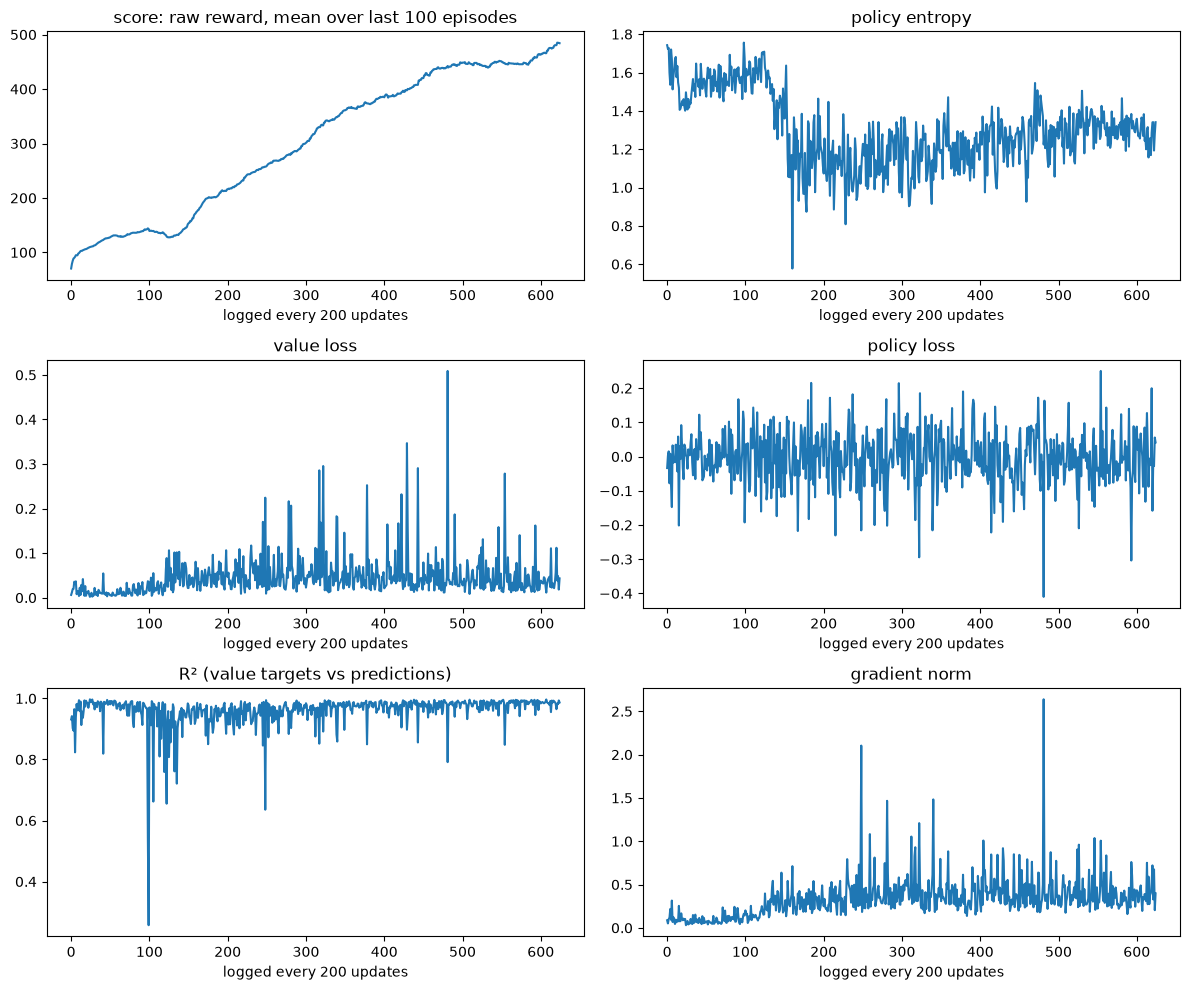

In [13]:
# plots: score + the debug quantities suggested in the notebook
h = {k: [row.get(k) for row in history] for k in history[0]}
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.ravel()
for ax, (k, title) in zip(axes, [
    ("reward_mean_100", "score: raw reward, mean over last 100 episodes"),
    ("entropy", "policy entropy"),
    ("value_loss", "value loss"),
    ("policy_loss", "policy loss"),
    ("r_squared", "R\u00b2 (value targets vs predictions)"),
    ("grad_norm", "gradient norm"),
]):
    vals = [v for v in h[k] if v is not None]
    ax.plot(vals)
    ax.set_title(title)
    ax.set_xlabel("logged every 200 updates")
plt.tight_layout()
plt.savefig("a2c_training.png", dpi=120)
plt.show()


In [14]:
# Stage 2: warm LR restart + halved entropy — lifts the trained policy
# (our ablation: 497 -> 763). Run this cell after stage 1 finishes.
#
# If the runtime died mid-run, first restore the checkpoint:
#   ck = torch.load("ckpt.pt", map_location=device)
#   model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
#   runner.step_var = ck["step"]

for g in optimizer.param_groups:
    g["lr"] = 2.3e-4
a2c.entropy_coef = 0.005

run_training(15_000_000)

step= 10080000 reward100=480.66875 entropy=1.184 vloss=0.0334 R2=0.983 |g|=0.37 ups=3514.6/s
step= 10240000 reward100=471.35 entropy=0.891 vloss=0.1358 R2=0.922 |g|=0.70 ups=1191.4/s
step= 10400000 reward100=453.759375 entropy=0.992 vloss=0.1323 R2=0.942 |g|=0.61 ups=726.6/s
step= 10560000 reward100=433.546875 entropy=0.924 vloss=0.0747 R2=0.957 |g|=0.56 ups=527.4/s
step= 10720000 reward100=403.990625 entropy=0.856 vloss=0.0522 R2=0.963 |g|=0.34 ups=416.7/s
step= 10880000 reward100=378.990625 entropy=0.721 vloss=0.0436 R2=0.964 |g|=0.37 ups=346.4/s
step= 11040000 reward100=364.953125 entropy=0.718 vloss=0.0257 R2=0.981 |g|=0.37 ups=297.6/s
step= 11200000 reward100=360.834375 entropy=0.656 vloss=0.0371 R2=0.964 |g|=0.37 ups=261.9/s
step= 11360000 reward100=362.278125 entropy=0.641 vloss=0.0217 R2=0.989 |g|=0.48 ups=234.6/s
step= 11520000 reward100=369.459375 entropy=0.764 vloss=0.0355 R2=0.985 |g|=0.56 ups=213.0/s
step= 11680000 reward100=381.946875 entropy=1.041 vloss=0.0491 R2=0.978 |

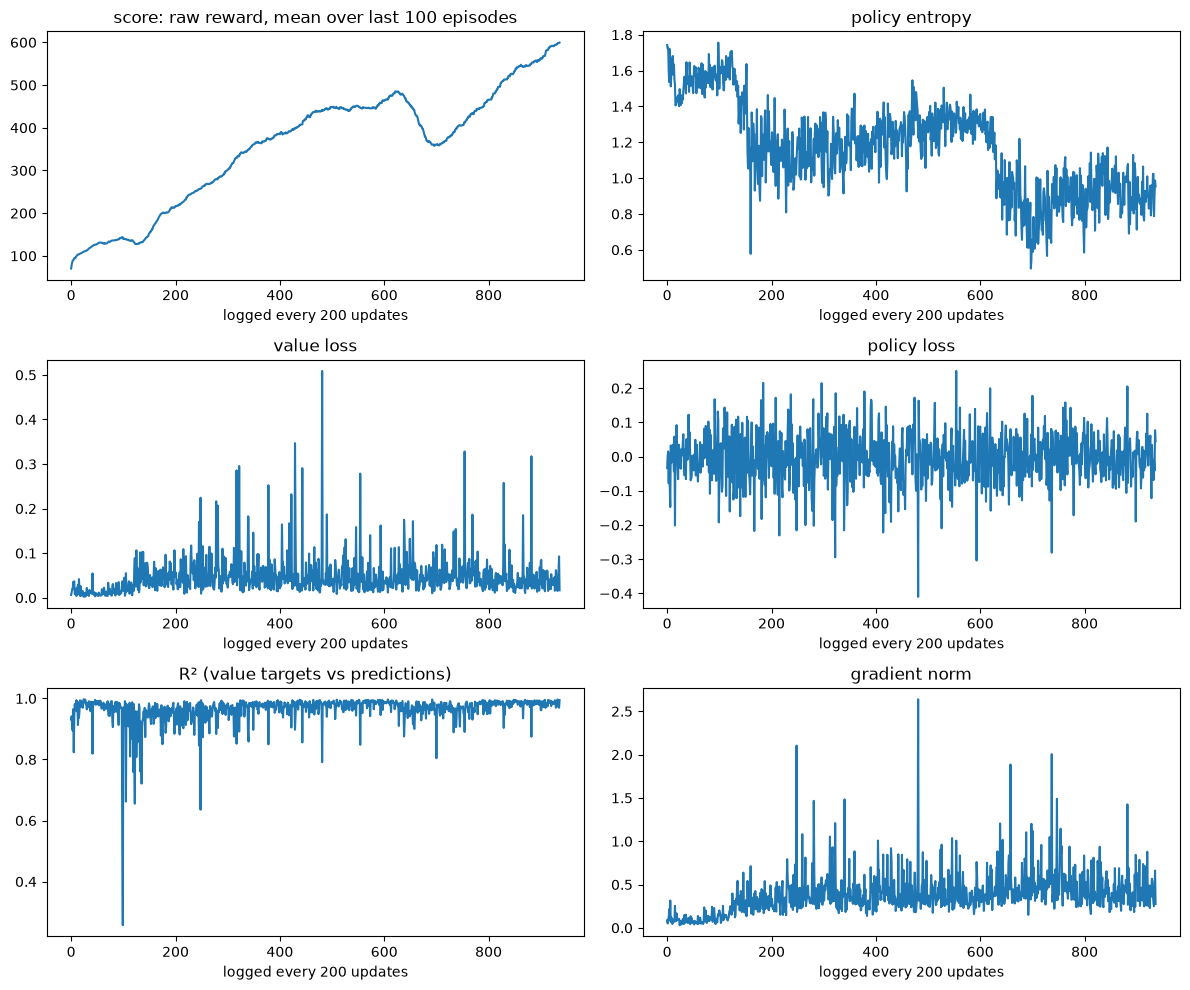

In [15]:
h = {k: [row.get(k) for row in history] for k in history[0]}
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.ravel()
for ax, (k, title) in zip(axes, [
    ("reward_mean_100", "score: raw reward, mean over last 100 episodes"),
    ("entropy", "policy entropy"),
    ("value_loss", "value loss"),
    ("policy_loss", "policy loss"),
    ("r_squared", "R² (value targets vs predictions)"),
    ("grad_norm", "gradient norm"),
]):
    vals = [v for v in h[k] if v is not None]
    ax.plot(vals)
    ax.set_title(title)
    ax.set_xlabel("logged every 200 updates")
plt.tight_layout()
plt.savefig("a2c_training.png", dpi=120)
plt.show()


In [17]:
final_scores = [h["reward_mean_100"] for h in history if h["reward_mean_100"] is not None]
print(f"\nFINAL reward_mean_100 = "
      f"{final_scores[-1] if final_scores else None}"
      f"{'' if final_scores else ' (see TensorBoard: Episodes/reward_mean_100)'}")


FINAL reward_mean_100 = 599.390625


### Target networks?

You may recall a technique called "target networks" we used a few weeks ago when we trained a DQN agent to play Atari Breakout and wonder why we have not suggested using them here. The answer is that this is more historical than practical.

While the "chasing the target" problem is still present in actor-critic value estimation and target networks do show up in follow-up papers, the original A3C/A2C papers do not mention them and do not explain this omission.

The hypothesis why this may not be a big deal (compared to Q-learning) goes like this. An A3C/A2C agent selects actions based on policy, not an epsilon greedy exploration function, for which the argmax can change drastically due to tiny errors in function approximation. Therefore, errors in the value target caused by target chasing will cause less damage.

Also, the actor-critic gradient relies on the advantage function $A(s_t, a_t) = Q(s_t, a_t) - V(s_t)$. Compare this to the $Q$-function $Q(s_t, a_t) = r(s_t, a_t) + \gamma \cdot \mathbb{E}_{s_{t+1} \mid s_t, a_t} V(s_{t+1})$ used in Q-learning and SARSA: we would expect that any bias in $V$-function approximation will be carried over from $V(s_{t+1})$ to $V(s_t)$ by gradient updates. However, in the formula for the advantage function the two approximations ($Q$-function and $V$-function) come with opposite signs, and thus the errors will cancel out.

The last reason may be computational. Authors were concerned to beat existent algorithms in the wall-clock learning time, and any overhead of parameter copying (target network update) counted against this goal.